---
title: "L7-08 · Reproducible quantum causal benchmarks"
short_title: "Reproducible quantum causal benchmarks"
subtitle: "A causal benchmark must score what a method claims, interventions and structure rather than prediction on the training distribution, and its numbers mean something only when generators, seeds, splits, tuning and resources are fixed in advance and reported."
description: "Design and audit a benchmark that separates predictive accuracy from causal-structure and intervention recovery, using seeded ground truth, held-out interventions, matched tuning, ablations and complete reporting."
tags: [level-7, coursebook]
---

(lesson-l7-08)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 120 minutes  
**Big idea.** A causal benchmark must score what a method claims, interventions and structure rather than prediction on the training distribution, and its numbers mean something only when generators, seeds, splits, tuning and resources are fixed in advance and reported.  
**Before this lesson.** [L7-03](#lesson-l7-03), [L7-05](#lesson-l7-05), [L7-06](#lesson-l7-06)  
**Lab.** [Quantum causal inference](../../labs/11-quantum-causal-inference.ipynb)
:::

## What you will be able to do

- Prove that two causal models with the same observational distribution receive identical scores from any observational metric, and design a held-out intervention that separates them, classically and for quantum channels.
- Compute and interpret structural Hamming distance, held-out prediction error and interventional error for estimated graphs, and explain why they can rank methods differently.
- Build a seeded benchmark with validation-only tuning, strong and trivial baselines, and an ablation, and detect label leakage, scale artifacts and test-set selection in its results.
- Write a benchmark report that states generator, seeds, splits, tuning budget, metric conventions and counted resources, and limits its claims to what was tested.

## Why this matters

Here are two models of the same two variables. In the first, $X$ causes $Y$ with coefficient 1. In the second, a hidden $U$ drives both, and $X$ causes $Y$ with coefficient $0.5$. They produce exactly the same Gaussian distribution of $(X, Y)$, with covariance $\begin{pmatrix} 2 & 2 \\ 2 & 3.5 \end{pmatrix}$. Every predictor you could train, and every held-out prediction score you could compute, treats them identically. Yet if you set $X$ by hand, the first model says $Y$ moves one for one and the second says $\mathbb{E}[Y \mid do(X = x)] = 0.5\,x$. A benchmark that measures only prediction cannot tell a method that learned the right one from a method that learned the wrong one.

Quantum causal learning inherits this problem and adds its own: a channel learned from one family of preparations and measurements can be wrong on every other family, and simulations can hide resource costs that hardware would expose ([L7-06](#lesson-l7-06)). The cure is not a cleverer method but a better experiment about methods. This lesson builds one: a seeded generator with exact interventional answers, metrics that separate prediction from structure from intervention, a quantum held-out test, and a small harness in which you can watch four classic failures (one lucky seed, leaked labels, scale artifacts and tuning on the test set) happen and be caught.

:::{dropdown} Key terms

**Ground-truth generator**
: A seeded program that produces a causal model (graph and mechanisms), data from it, and exact answers to held-out interventional questions.

**Held-out intervention**
: An intervention, or for quantum processes a preparation and measurement setting, that is used only for testing and differs from every training condition.

**Structural Hamming distance (SHD)**
: The number of node pairs whose edge state (absent, $i \to j$, $j \to i$) differs between two graphs; in this lesson a reversed edge counts 1.

**Interventional error**
: The error of predicted means $\mathbb{E}[X_i \mid do(X_j = c)]$ against the exact values, averaged over held-out interventions; here normalized by $\operatorname{Var}(X_i)$.

**Ablation**
: A controlled removal or change of one ingredient (a feature, a data source, a piece of information) to test how much a result depends on it.

**Data leakage**
: Any path by which information about the test answers reaches the method or its tuning, such as labels in causal order or choices made on test scores.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_08 as _lessonfigs

## Prediction is not intervention

:::{prf:definition} Causal benchmark task
:label: def-l7-08-task
A **causal benchmark task** consists of (i) a ground-truth generator $G$ that maps a seed $s$ to a causal model $\mathcal{C}_s$ (a graph with mechanisms, or a quantum process); (ii) disjoint seed sets for validation, test and, ideally, a fresh confirmation run; (iii) training data drawn from $\mathcal{C}_s$ under the training conditions; (iv) held-out queries, including interventions not present in training, with exact answers computed from $\mathcal{C}_s$; (v) metrics with stated conventions; and (vi) a resource budget (samples, shots, circuits, tuning trials, compute) that is the same for every method compared.
:::

Throughout, the classical models are linear structural causal models $X = XB + E$ with samples as rows, $B_{ij} \ne 0$ meaning an edge $i \to j$, and independent $N(0, 1)$ noise $E$ [@peters]. An intervention $do(X_j = c)$ deletes the incoming edges of $j$ and fixes $X_j = c$. With zero-mean noise its effect on the means is exact:

$$
\mathbb{E}[X \mid do(X_j = c)] = c\, e_j^{\top} (I - B_{(j)})^{-1}, \qquad B_{(j)} = B \text{ with column } j \text{ set to } 0
$$ (eq-l7-08-do)

:::{prf:proposition} Observationally equivalent models cannot be ranked by observational scores
:label: prop-l7-08-twins
Let model A be $X \sim N(0, 2)$, $Y = X + e$ with $\operatorname{Var} e = 1.5$, and model B be $X = U + e_X$, $Y = 0.5\,X + U + e_Y$ with $U, e_X, e_Y$ independent $N(0, 1)$. Both give $(X, Y) \sim N\big(0, \begin{pmatrix} 2 & 2 \\ 2 & 3.5 \end{pmatrix}\big)$. Hence every score that depends on the data only through the observational distribution (held-out likelihood, held-out prediction error, any predictor's accuracy) has the same distribution under A and B. But $\mathbb{E}[Y \mid do(X = x)] = x$ under A and $0.5\,x$ under B.
:::

:::{prf:proof}
Both models are linear in independent Gaussians, so $(X, Y)$ is a zero-mean Gaussian vector, determined by its covariance. Model A: $\operatorname{Var} X = 2$, $\operatorname{Cov}(X, Y) = \operatorname{Var} X = 2$, $\operatorname{Var} Y = 2 + 1.5 = 3.5$. Model B: $\operatorname{Var} X = 1 + 1 = 2$, $\operatorname{Cov}(X, Y) = 0.5\operatorname{Var} X + \operatorname{Cov}(U, X) = 1 + 1 = 2$, $\operatorname{Var} Y = 0.25\cdot 2 + 1 + 2\cdot 0.5\operatorname{Cov}(X, U) + 1 = 0.5 + 1 + 1 + 1 = 3.5$. Equal covariances give equal distributions, so any function of samples from them has equal distribution. Under $do(X = x)$ the edge $U \to X$ is cut; in A, $\mathbb{E}[Y] = x$; in B, $\mathbb{E}[Y] = 0.5\,x + \mathbb{E}[U] = 0.5\,x$.
:::

:::{figure} ../../_static/animations/l7_08_observational_twins.mp4
:alt: Two small causal graphs, one direct and one confounded, and a scatter plot where their point clouds overlap with one regression line; then the confounding arrow is cut and the two interventional lines separate.
:width: 100%

Same data, different interventions: graph surgery splits two models that no predictive score can tell apart.
:::

:::{dropdown} What the animation shows
Model A ($X \to Y$ with weight 1.0) is drawn in violet and model B ($U \to X$, $U \to Y$, $X \to Y$ with weight 0.5) in amber, with the shared covariance $\Sigma = \begin{pmatrix} 2 & 2 \\ 2 & 3.5 \end{pmatrix}$. 140 seeded samples from each model fill one scatter plot; the clouds are indistinguishable and share the regression line $\mathbb{E}[Y \mid X = x] = x$, so any predictor scores the same on both. Then the arrow $U \to X$ in model B is crossed out and $X$ is boxed as $do(X)$. The amber cloud is redrawn with $X$ set independently of $U$, and two lines appear: model A's $\mathbb{E}[Y \mid do(X = x)] = x$ and model B's $\mathbb{E}[Y \mid do(X = x)] = 0.5\,x$. The closing line says that only a held-out intervention can rank them.
:::

Proposition [](#prop-l7-08-twins) is the benchmark version of the identification problem of [L7-05](#lesson-l7-05): if the training distribution does not identify the target, then neither does any test computed from that distribution. The remedy is a test set that contains the target itself, an intervention the method never saw.

## Metrics that measure different things

:::{prf:definition} Three metrics
:label: def-l7-08-metrics
For an estimated weighted graph $\hat W$ and truth $B$ on $d$ nodes: the **structural Hamming distance** $\mathrm{SHD}(\hat W, B)$ was introduced by Tsamardinos, Brown and Aliferis for partially directed graphs [@tsamardinos2006]; applied here to DAGs, it is the number of unordered pairs $\{i, j\}$ whose state ($\text{no edge}$, $i \to j$, $j \to i$) differs, so a missing, extra or reversed edge each counts 1 (some papers count a reversal as 2; always state the convention). The **held-out prediction error** is $\frac1d\sum_i \mathrm{MSE}_i/\operatorname{Var}(X_i)$ on test samples, predicting $X_i$ either from all other variables or from its estimated parents. The **interventional error** is $\frac1d\sum_j \frac{1}{d-1}\sum_{i\ne j} \big(\hat\mu_{ij} - \mu_{ij}\big)^2/\operatorname{Var}(X_i)$, where $\mu_{ij} = \mathbb{E}[X_i \mid do(X_j = c_j)]$ from [](#eq-l7-08-do), $c_j$ is two observational standard deviations of $X_j$, and $\hat\mu_{ij}$ is the method's prediction. Dividing by variances and intervening at a fixed number of standard deviations make both errors independent of the units of the variables.
:::

:::{figure} ../../_static/animations/l7_08_metrics_disagree.mp4
:alt: A true four-node graph next to an estimate that changes three times: missing a weak edge, missing a strong edge, and with a weak extra edge; a table lists SHD 1 for each and very different interventional errors.
:width: 100%

Three estimates at the same SHD of 1 differ by more than a factor of 20 in interventional error.
:::

:::{dropdown} What the animation shows
The true graph has edges $A \to B$ (1.5), $A \to C$ (0.6), $B \to D$ (1) and $C \to D$ (0.8), with unit noise. Three estimates are shown in turn beside it. Each estimate keeps the other weights at their true values. Missing the edge $A \to C$ gives SHD 1 and interventional error 0.100. Missing the strong edge $A \to B$ gives SHD 1 and interventional error 0.345. Adding a weak extra edge $B \to C$ with weight 0.1 gives SHD 1 and interventional error 0.015. The closing text reads: SHD counts edges and ignores how strong they are; report both structure and interventional error.
:::

:::{prf:remark} Trivial baselines expose metric quirks
:label: rem-l7-08-empty
The empty graph has SHD equal to the number of true edges and predicts no interventional effect at all. It is a mandatory baseline: in the benchmark below, the empty graph scores an SHD of 7.60 while a learner that uses a random variable order scores 6.00, only modestly better given the spread over seeds. A method that does not clearly beat the empty graph has not shown structure recovery, whatever its other scores.
:::

:::{note} Continuous structure learners and their evaluation
Score-based learners such as NOTEARS turn the combinatorial acyclicity constraint into a smooth equality constraint on a weighted adjacency matrix and output a weighted graph [@notears]; libraries such as causal-learn package constraint-based, score-based and functional-model-based discovery methods behind one interface [@causallearn]. Either can be dropped into the harness below as a learner. The harness then asks the same three questions of each, with the same seeds, splits and tuning budget.
:::

## A quantum held-out test

For quantum processes the role of an intervention is played by the experimenter's local operations, such as the choice of preparation and measurement; quantum causal modeling in the process-matrix formalism is built on such operations [@costa]. Consider the one-qubit dephasing family

$$
\mathcal{E}_p(\rho) = (1-p)\rho + pZ\rho Z, \qquad 0 \le p \le 1
$$ (eq-l7-08-dephasing)

:::{prf:proposition} Training on Z-basis settings cannot identify p
:label: prop-l7-08-dephasing
If training uses only the preparations $|0\rangle, |1\rangle$ and $Z$ measurements, the outcome distribution is the same for every $p$: the outcome equals the input with probability 1. With the held-out preparation $|{+}\rangle$ and an $X$ measurement, the output Bloch vector is $(1 - 2p, 0, 0)$ and $P(+) = 1 - p$, so $p$ is identified and estimated by $\hat p = 1 - \hat f_+$, where $\hat f_+$ is the observed frequency of $+$. This makes Example (coherence hidden by the measurement basis) of [L7-05](#lesson-l7-05), which compares $p = 0$ with complete dephasing $p = 1/2$, quantitative for the whole family.
:::

:::{prf:proof}
$Z|0\rangle\langle 0|Z = |0\rangle\langle 0|$ and likewise for $|1\rangle$, so $\mathcal{E}_p$ fixes both and the $Z$ statistics do not depend on $p$. For $|{+}\rangle\langle{+}| = \tfrac12(I + X)$, $ZXZ = -X$ gives $\mathcal{E}_p(|{+}\rangle\langle{+}|) = \tfrac12\big(I + (1 - 2p)X\big)$, and $P(+) = \tfrac12(1 + (1 - 2p)) = 1 - p$.
:::

:::{figure} ../../_static/animations/l7_08_quantum_held_out.mp4
:alt: A Bloch sphere where the identity and the dephasing channel send the poles to the poles identically; then a vector along the x axis shrinks under dephasing while the identity keeps it.
:width: 100%

Identity and dephasing agree on every Z-basis training setting; the held-out $|{+}\rangle$ preparation with an $X$ measurement separates them.
:::

:::{dropdown} What the animation shows
A Bloch sphere is drawn with the channel $\mathcal{E}_p(\rho) = (1-p)\rho + pZ\rho Z$; the identity is $p = 0$ and dephasing has $p > 0$. Training inputs $|0\rangle$ and $|1\rangle$ with $Z$ measurements give overlapping violet (identity) and red (dephasing) vectors at the poles: $P(\text{same}) = 1$ for every $p$, so the training data cannot tell them apart. Then the held-out input $|{+}\rangle$ with an $X$ measurement is shown. The identity keeps the vector at the sphere's surface on the $x$ axis, while under dephasing the red vector shrinks to Bloch length $1 - 2p$ as $p$ steps from 0 to 0.5, and the readout gives $P(+) = 1 - p$: 0.9, 0.8, down to 0.5, against 1.0 for the identity. The closing line: a benchmark without this test rewards both.
:::

:::{prf:example} The same test as a Choi-state observable
:label: ex-l7-08-choi
The held-out setting has a static counterpart. In the normalized Choi state of $\mathcal{E}_p$ (the channel applied to half of $|\Phi^+\rangle$), $\langle X\otimes X\rangle = 1 - 2p$ while $\langle Z\otimes Z\rangle = 1$ for every $p$. A random-Pauli classical shadow [@shadows] of the Choi state estimates the decisive weight-2 observable at single-snapshot variance $9 - (1 - 2p)^2 \le 9$, as computed in [L7-07](#lesson-l7-07). Whether one probes with held-out instruments or estimates the right Choi-state observables, the test must contain information that the training settings lack.
:::

Quantum causal discovery algorithms take richer objects as input, such as a process matrix, from which causal order and mechanisms are read off [@giarmatzi]; light-touch schemes test candidate causal structures from coarse-grained two-time measurements [@hypothesis]. The benchmark logic is the same at that scale: specify the generator of processes, keep some instruments for testing only, and report structure recovery separately from predictive fit.

## Seeds, splits, tuning and ablations

:::{prf:algorithm} A minimal reproducible causal benchmark
:label: alg-l7-08-protocol
1. Fix the generator, its parameters and the code version; draw node labels uniformly at random for each seed (labels left in causal order leak information about the answer into the input, a form of data leakage [@kaufman2012]). 2. Fix disjoint seed sets before running anything: validation (here 0 to 19), test (100 to 119) and fresh confirmation (200 to 219). 3. Give every learner the same tuning grid and budget, and tune on validation seeds only. 4. Include a trivial baseline (empty graph), a predictive model, a null model (random order) and a reference with privileged information (true order). 5. Score the test seeds once, on all metrics, and report mean and spread over seeds. 6. Run at least one ablation that removes information a method might exploit unintentionally. 7. Archive generator, seeds, raw outputs and the analysis script together.
:::

```{mermaid}
graph LR
  G[Seeded generator] --> P[Permute labels]
  P --> TR[Training data]
  P --> HI[Held-out interventions]
  V[Validation seeds] --> TU[Tune each learner]
  TU --> L[Learners and baselines]
  TR --> L
  L --> M[SHD, prediction, intervention]
  HI --> M
  M --> R[Report over test seeds]
  R --> F[Fresh-seed confirmation]
```

*The benchmark pipeline. Test answers flow only into the metrics; tuning sees validation seeds only; a fresh seed set confirms the final comparison.*

The complete harness (the same functions the figures and animations use), followed by a driver that tunes on validation seeds, scores the test seeds, and runs the leakage, units and test-set-selection experiments, then checks the observational twins and the quantum held-out test. Numpy only, seeded throughout.


In [2]:
import math
import numpy as np

D, N_TRAIN, P_EDGE, C_DO, TAU = 6, 500, 0.5, 2.0, 3.0
LEARNERS = ['predict from all others', 'empty graph', 'column order', 'variance sort', 'random order', 'true order']
ORDERED = LEARNERS[2:]
GRID = [2.0, 3.0, 4.0, 6.0, 8.0, 12.0]
VAL_SEEDS, TEST_SEEDS, FRESH_SEEDS = list(range(0, 20)), list(range(100, 120)), list(range(200, 220))


def make_task(seed, d=D, n=N_TRAIN, p=P_EDGE, permute=True, rescale=False):
    """A seeded ground-truth task: random DAG, train and test samples, and held-out interventions."""
    rng = np.random.default_rng(seed)
    B = np.triu(rng.uniform(0.5, 2.0, (d, d)) * rng.choice([-1, 1], (d, d)) * (rng.random((d, d)) < p), k=1)
    perm = rng.permutation(d) if permute else np.arange(d)
    B = B[np.ix_(perm, perm)]                       # relabel nodes so that index order is not causal order
    s = 10 ** rng.uniform(-1, 1, d)                # always drawn, so both variants share the same noise
    s = s if rescale else np.ones(d)
    B = B * s[None, :] / s[:, None]                 # change of units X_i -> s_i X_i keeps the graph
    A = np.linalg.inv(np.eye(d) - B)

    def sample(m):
        return (rng.normal(size=(m, d)) * s) @ A

    var = np.diag(A.T @ np.diag(s ** 2) @ A)        # exact observational variances
    return dict(B=B, train=sample(n), test=sample(n), var=var,
                do_mean=np.array([do_mean(B, j, C_DO * math.sqrt(var[j])) for j in range(d)]))


def do_mean(W, j, c):
    """E[X | do(X_j = c)] for the linear SCM with weights W and zero-mean noise."""
    Wj = W.copy()
    Wj[:, j] = 0
    return c * np.linalg.inv(np.eye(len(W)) - Wj)[j]


def fit_order(X, order, tau=TAU):
    """Regress each variable on the variables before it in `order` (OLS) and keep coefficients with |t| >= tau.

    The t statistic (coefficient over its standard error) does not change with the units of the variables."""
    n, d = X.shape
    W = np.zeros((d, d))
    for k in range(1, d):
        i, pa = order[k], list(order[:k])
        A = X[:, pa]
        w, *_ = np.linalg.lstsq(A, X[:, i], rcond=None)
        s2 = np.sum((X[:, i] - A @ w) ** 2) / (n - len(pa))
        se = np.sqrt(s2 * np.diag(np.linalg.inv(A.T @ A)))
        W[pa, i] = np.where(np.abs(w / se) >= tau, w, 0.0)
    return W


def shd(W1, W2):
    """Structural Hamming distance between the supports of two weighted adjacency matrices (reversal = 1)."""
    a, b = W1 != 0, W2 != 0
    d = len(a)
    return int(sum((a[i, j], a[j, i]) != (b[i, j], b[j, i]) for i in range(d) for j in range(i + 1, d)))


def obs_error(X, Xt, W=None):
    """Held-out prediction error: predict each X_i from all other variables (W None) or from its parents in W."""
    errs = []
    for i in range(X.shape[1]):
        cols = [j for j in range(X.shape[1]) if j != i] if W is None else list(np.flatnonzero(W[:, i]))
        if cols:
            w = np.linalg.lstsq(X[:, cols], X[:, i], rcond=None)[0]
            pred = Xt[:, cols] @ w
        else:
            pred = np.zeros(len(Xt))
        errs.append(np.mean((Xt[:, i] - pred) ** 2) / np.var(Xt[:, i]))
    return float(np.mean(errs))


def int_error(task, W=None, X=None):
    """Interventional error of a weighted DAG W, or (W None) of conditioning E[X | X_j = c] estimated from X."""
    d = len(task["B"])
    S = np.cov(X, rowvar=False) if W is None else None
    out = []
    for j in range(d):
        c = C_DO * math.sqrt(task["var"][j])        # intervene at two standard deviations of X_j
        pred = c * S[j] / S[j, j] if W is None else do_mean(W, j, c)
        keep = [i for i in range(d) if i != j]
        out.append(np.mean((pred[keep] - task["do_mean"][j][keep]) ** 2 / task["var"][keep]))
    return float(np.mean(out))


def true_order(B):
    """A topological order of the DAG with weights B."""
    d, order, left = len(B), [], set(range(len(B)))
    while left:
        src = [i for i in sorted(left) if not any(B[j, i] != 0 for j in left)]
        order.append(src[0])
        left.remove(src[0])
    return np.array(order)


def orders_for(name, task, seed):
    """The variable order an order-based learner uses."""
    X = task["train"]
    return {"column order": np.arange(D), "variance sort": np.argsort(X.var(axis=0)),
            "random order": np.random.default_rng(10_000 + seed).permutation(D),
            "true order": true_order(task["B"])}[name]


def run_benchmark(seeds, taus=None, permute=True, rescale=False, full=True):
    """Rows (learner, seed, SHD, held-out prediction error, interventional error); taus maps learner -> threshold.

    full=False computes SHD only (enough for tuning thresholds)."""
    taus = taus or {}
    rows = []
    for seed in seeds:
        t = make_task(seed, permute=permute, rescale=rescale)
        X, Xt = t["train"], t["test"]
        if full:
            rows.append(("predict from all others", seed, np.nan, obs_error(X, Xt), int_error(t, X=X)))
            W0 = np.zeros((D, D))
            rows.append(("empty graph", seed, shd(W0, t["B"]), obs_error(X, Xt, W0), int_error(t, W0)))
        for name in ORDERED:
            W = fit_order(X, orders_for(name, t, seed), taus.get(name, TAU))
            rows.append((name, seed, shd(W, t["B"])) + ((obs_error(X, Xt, W), int_error(t, W)) if full else (np.nan, np.nan)))
    return rows


def tune(seeds, grid=GRID, **task_options):
    """Per-learner threshold with the smallest mean SHD on the given (validation) seeds."""
    res = {tau: run_benchmark(seeds, {L: tau for L in ORDERED}, full=False, **task_options) for tau in grid}
    return {L: min(grid, key=lambda tau: summarize(res[tau], L, 2)[0]) for L in ORDERED}


def summarize(rows, learner, col):
    """Mean and sample standard deviation of one column for one learner."""
    v = np.array([r[col] for r in rows if r[0] == learner], dtype=float)
    return float(np.mean(v)), (float(np.std(v, ddof=1)) if len(v) > 1 else 0.0)


def null_model_shd(tasks, k, tau):
    """Mean SHD of 'null model' k: a fixed random variable order (seed 500 + k), whatever the task."""
    order = np.random.default_rng(500 + k).permutation(D)
    return float(np.mean([shd(fit_order(t["train"], order, tau), t["B"]) for t in tasks]))


# ---- 1. tune each learner's threshold on validation seeds only, then score the test seeds ----
taus = tune(VAL_SEEDS)
print("thresholds chosen on validation seeds:", taus)


def report(rows, title):
    print(title)
    for L in LEARNERS:
        s, o, i = (summarize(rows, L, c) for c in (2, 3, 4))
        shd_txt = "   not a graph" if np.isnan(s[0]) else f"{s[0]:5.2f} +- {s[1]:4.2f}"
        print(f"  {L:24s} SHD {shd_txt}   prediction {o[0]:.3f}   interventional {i[0]:.3f}")


main = run_benchmark(TEST_SEEDS, taus)
report(main, "test seeds 100-119, node labels permuted")
# ---- 2. leakage: the generator leaves node labels in causal order (validation and test alike) ----
leak = run_benchmark(TEST_SEEDS, tune(VAL_SEEDS, permute=False), permute=False)
print("labels not permuted: column order SHD", summarize(leak, "column order", 2)[0],
      "= true order SHD", summarize(leak, "true order", 2)[0])
# ---- 3. ablation: change the units of every variable (the causal graph is unchanged) ----
units = run_benchmark(TEST_SEEDS, taus, rescale=True)
for L in ("variance sort", "true order"):
    print(f"random units: {L:13s} SHD {summarize(main, L, 2)[0]:.2f} -> {summarize(units, L, 2)[0]:.2f}")
# ---- 4. selecting the best of 30 null models on the test seeds ----
test_tasks = [make_task(s) for s in TEST_SEEDS]
fresh_tasks = [make_task(s) for s in FRESH_SEEDS]
test = [null_model_shd(test_tasks, k, taus["random order"]) for k in range(30)]
fresh = [null_model_shd(fresh_tasks, k, taus["random order"]) for k in range(30)]
b = int(np.argmin(test))
print(f"best null model on test: {test[b]:.2f} (mean of 30: {np.mean(test):.2f});"
      f" same model on fresh seeds: {fresh[b]:.2f} (mean of 30: {np.mean(fresh):.2f})")

# ---- 5. observational twins: same covariance, different interventions ----
cov_A = np.array([[2.0, 2.0], [2.0, 2.0 + 1.5]])                      # X ~ N(0, 2), Y = X + e, Var e = 1.5
cov_B = np.array([[1 + 1, 0.5 * 2 + 1], [0.5 * 2 + 1, 0.25 * 2 + 1 + 2 * 0.5 + 1]])   # X = U + eX, Y = 0.5 X + U + eY
assert np.allclose(cov_A, cov_B)
print("same covariance", cov_A.tolist(), "; do-slopes 1.0 (A) and 0.5 (B)")

# ---- 6. quantum held-out test: E_p(rho) = (1 - p) rho + p Z rho Z ----
Z = np.diag([1.0, -1.0])
plus = np.full((2, 2), 0.5)
rng = np.random.default_rng(42)
p_true, shots = 0.3, 738
for p in (0.0, 0.3, 0.5):
    out0 = (1 - p) * np.diag([1.0, 0]) + p * Z @ np.diag([1.0, 0]) @ Z    # |0> through the channel
    outp = (1 - p) * plus + p * Z @ plus @ Z                              # |+> through the channel
    print(f"p = {p}: P(0 | |0>, Z) = {out0[0, 0]:.1f}   P(+ | |+>, X) = {np.sum(outp) / 2:.2f}")
k = rng.binomial(shots, 1 - p_true)
print(f"held-out estimate from {shots} X shots: p_hat = {1 - k / shots:.3f} (true {p_true})")

thresholds chosen on validation seeds: {'column order': 12.0, 'variance sort': 3.0, 'random order': 8.0, 'true order': 3.0}
test seeds 100-119, node labels permuted
  predict from all others  SHD    not a graph   prediction 0.183   interventional 0.997
  empty graph              SHD  7.60 +- 1.88   prediction 1.002   interventional 0.761
  column order             SHD  6.45 +- 3.10   prediction 0.534   interventional 0.954
  variance sort            SHD  1.05 +- 1.64   prediction 0.480   interventional 0.170
  random order             SHD  6.00 +- 2.34   prediction 0.477   interventional 0.863
  true order               SHD  0.00 +- 0.00   prediction 0.465   interventional 0.003


labels not permuted: column order SHD 0.1 = true order SHD 0.1
random units: variance sort SHD 1.05 -> 4.55
random units: true order    SHD 0.00 -> 0.00


best null model on test: 5.65 (mean of 30: 6.58); same model on fresh seeds: 6.05 (mean of 30: 6.13)
same covariance [[2.0, 2.0], [2.0, 3.5]] ; do-slopes 1.0 (A) and 0.5 (B)
p = 0.0: P(0 | |0>, Z) = 1.0   P(+ | |+>, X) = 1.00
p = 0.3: P(0 | |0>, Z) = 1.0   P(+ | |+>, X) = 0.70
p = 0.5: P(0 | |0>, Z) = 1.0   P(+ | |+>, X) = 0.50
held-out estimate from 738 X shots: p_hat = 0.272 (true 0.3)


Thresholds are tuned per learner on the validation seeds, as $|t|$-statistics of the regression coefficients (the $t$ statistic does not change with units): column order 12, variance sort 3, random order 8, true order 3. The test results, mean ± sample standard deviation over 20 seeds:

| learner | SHD | held-out prediction error | interventional error |
|---|---|---|---|
| predict from all others | not a graph | 0.183 ± 0.120 | 0.997 ± 0.421 |
| empty graph | 7.60 ± 1.88 | 1.002 ± 0.002 | 0.761 ± 0.375 |
| column order | 6.45 ± 3.10 | 0.534 ± 0.128 | 0.954 ± 0.587 |
| variance sort | 1.05 ± 1.64 | 0.480 ± 0.104 | 0.170 ± 0.332 |
| random order | 6.00 ± 2.34 | 0.477 ± 0.117 | 0.863 ± 0.597 |
| true order | 0.00 ± 0.00 | 0.465 ± 0.114 | 0.003 ± 0.003 |

The predictor that uses all other variables has by far the best held-out prediction error (0.183) and the worst interventional error (0.997), worse even than the empty graph's 0.761: conditioning on $X_j = c$ is not intervening on it. The true-order reference recovers the graph exactly on every test seed (SHD 0.00).


In [3]:
_show(_lessonfigs.benchmark_explorer())

**Explore.** Each learner's held-out prediction error against its interventional error (left) and its mean SHD (right), with standard errors over seeds. Drag the slider to use 1, 2, 5, 10 or 20 test seeds and watch rankings settle.

:::{dropdown} What the figure shows
The first panel plots, on log scales, held-out prediction error on the horizontal axis against interventional error on the vertical axis for six methods: the predictor that uses all other variables (best prediction, about 0.18, but interventional error about 1.0), the empty graph (prediction error 1, interventional error about 0.76), column order and random order (prediction about 0.5, interventional error about 0.95 and 0.86), variance sort (interventional error about 0.17) and the true-order reference (about 0.003). The second panel shows mean SHD with error bars: empty graph about 7.6, column order about 6.5, random order about 6.0, variance sort about 1.0, true order 0. With a single seed the error bars vanish and the ordering can differ; with 20 seeds the standard errors are small and the separation is clear.
:::

:::{figure} ../../_static/animations/l7_08_benchmark_failures.mp4
:alt: A bar chart of SHD for five learners that changes four times: one seed, twenty seeds, labels left in causal order, and random units; a final text compares the best of thirty null models on test and fresh seeds.
:width: 100%

Four ways a benchmark can mislead, computed with the harness: one lucky seed, leaked labels, a scale artifact, and selection on the test set.
:::

:::{dropdown} What the animation shows
Bars show SHD for the empty graph, column order, variance sort, random order and true order. First, a single seed (105): random order scores 1 and beats variance sort at 2. With 20 seeds, mean and standard deviation, the ranking reverses: random order 6.00, variance sort 1.05. Second, when the generator leaves node labels in causal order, the column-order learner drops from 6.45 to 0.10, identical to the true-order reference. Third, an ablation that changes the units of every variable raises variance sort from 1.05 to 4.55 while the graph is unchanged. Fourth, the best of 30 null models chosen on the test seeds scores 5.65 (mean of 30: 6.58), but on fresh seeds the same model scores 6.05 (mean of 30: 6.13).
:::


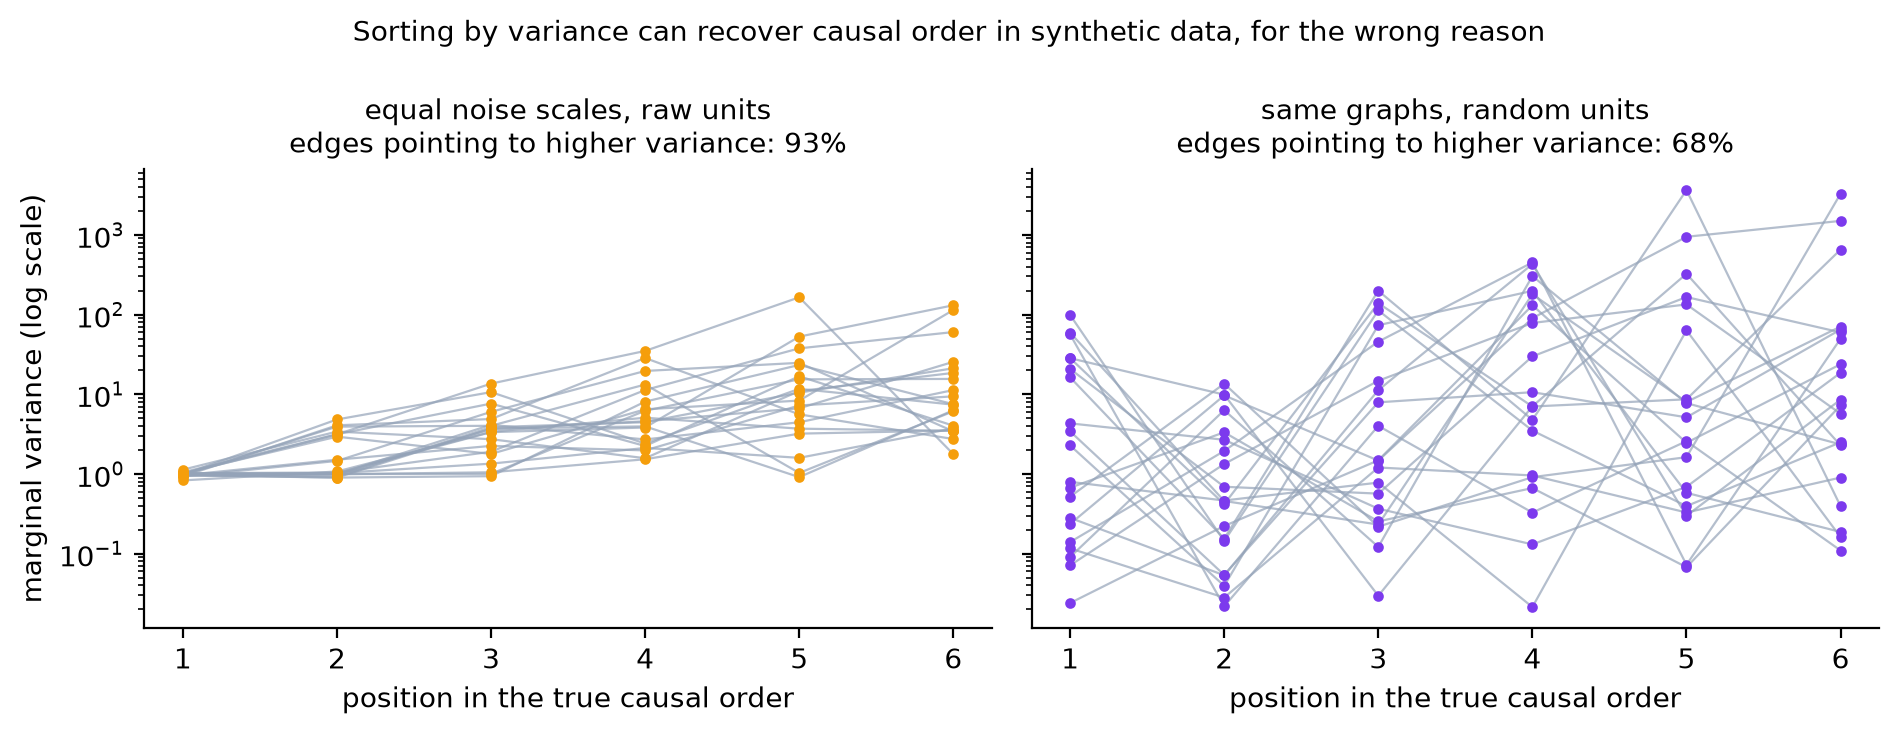

In [4]:
_show_mpl(_lessonfigs.variance_figure())

*Marginal variance along the true causal order for the 20 test graphs. With equal noise scales (left) variance tends to grow along the order, and 93% of edges point from lower to higher variance, so sorting by variance recovers much of the order. After a random change of units (right), which leaves every graph unchanged, the figure drops to 68% and the variance-sort learner's SHD rises from 1.05 to 4.55.*

:::{prf:proposition} Selection on the test set is optimistic
:label: prop-l7-08-selection
Let $S_1, \dots, S_k$ be test-set scores (lower is better) of $k$ methods with the same expected score $\mu$, and let $\hat\imath = \arg\min_i S_i$. Then $\mathbb{E}[S_{\hat\imath}] \le \mu$, while the score of method $\hat\imath$ on fresh, independent data has expectation $\mu$.
:::

:::{prf:proof}
$S_{\hat\imath} = \min_i S_i \le S_1$, so $\mathbb{E}[S_{\hat\imath}] \le \mathbb{E}[S_1] = \mu$. Fresh data are independent of the test data and hence of $\hat\imath$, so conditionally on $\hat\imath = i$ the fresh score has expectation $\mu_i = \mu$; averaging over $i$ gives $\mu$. In the harness the 30 null models are fixed variable orders, and because labels are permuted uniformly at random, each has the same expected SHD. The selected one looked 0.93 better than average on the test seeds (5.65 against 6.58) and was 0.08 better on fresh seeds (6.05 against 6.13), that is, ordinary.
:::

## Reporting, baselines and claims

:::{important} What a benchmark report must contain
Generator code and version; every seed set and how it was chosen; splits and the held-out interventions or instruments; the tuning grid, the budget per method and the data used for tuning; metric definitions and conventions (SHD reversal count, normalizations); all metrics for all methods, with spread over seeds and the number of seeds; counted resources (samples, shots, circuits, wall-clock) per method; for quantum hardware, the device, calibration data, compiled circuits, shot allocation and stopping rule; for simulations, the simulator and noise model, labeled as simulation. Raw outputs and the analysis script should reproduce every number in the paper.
:::

Baselines decide what a result means. Huang and collaborators showed that classical learners given data can be competitive with quantum models, and introduced a test, based on the geometry of the kernel matrices, for when a prediction advantage is possible at all [@advantage]; a quantum causal learner should face the strongest classical learner given the same data and budget, not a weak one. Schölkopf and coauthors link causal inference to the open machine-learning problems of transfer and generalization beyond the training distribution [@scholkopf], which is what held-out interventions test, and the broader program of causal AI asks systems to answer interventional and counterfactual queries, not only predictive ones [@bareinboim]. A benchmark is a model of that program at small scale; its synthetic ground truth validates performance for its generator, not for a physical system whose causal assumptions have not been checked.

:::{prf:remark} Scale artifacts are a property of the generator
:label: rem-l7-08-varsort
Why does variance grow along the order here? For a single edge $X \to Y$ with weight $b \ne 0$ and unit noises, $\operatorname{Var} Y = b^2 + 1 > 1 = \operatorname{Var} X$. With weights of magnitude at least $0.5$ and equal noise scales, such increases tend to accumulate along paths, although they are not guaranteed edge by edge. A method that is not invariant to units can exploit this without learning anything causal; the units ablation is the test. Reisach, Seiler and Weichwald call this property varsortability (they measure it over all pairs joined by a directed path, not only over edges), find it high in commonly used simulated additive-noise benchmarks, show that a simple baseline that sorts by variance and then regresses is competitive there, and report that the performance of several continuous structure learners drops after the data are standardized [@reisach2021]. The numbers above are for this lesson's generator only.
:::

## Worked example

:::{admonition} Designing the held-out test for a dephasing learner
:class: tip

A method claims to identify the dephasing parameter $p$ of $\mathcal{E}_p(\rho) = (1-p)\rho + pZ\rho Z$ from data. Design a benchmark that tests the claim, including a held-out setting, a metric, a shot budget for error at most $0.05$ with failure probability at most $0.05$, and an ablation.

1. Generator: draw $p$ uniformly from $[0, 1/2]$ for each seed, and simulate counts from the exact outcome probabilities; the seed sets for validation and test are fixed in advance.
2. Training conditions: the method's stated training settings. If they are only $|0\rangle, |1\rangle$ with $Z$ measurements, [](#prop-l7-08-dephasing) shows the training likelihood is flat in $p$, so any reported $p$ is a prior choice, not an estimate (compare the remark on priors in [L7-05](#lesson-l7-05)).
3. Held-out setting: prepare $|{+}\rangle$ and measure $X$; then $P(+) = 1 - p$ and $\hat p = 1 - \hat f_+$. Metric: $|\hat p - p|$ averaged over test seeds, plus coverage of any reported interval.
4. Budget: each shot is a Bernoulli outcome in $[0, 1]$, so Hoeffding's inequality [@hoeffding1963] gives $\Pr(|\hat f_+ - (1-p)| \ge \epsilon) \le 2e^{-2N\epsilon^2}$. Requiring $\le 0.05$ at $\epsilon = 0.05$ gives $N \ge \ln(40)/(2\cdot 0.0025) \approx 737.8$, so 738 shots per test seed. This is the same count as the $\pm1$ form $N \ge (2/\epsilon^2)\ln(2/\delta)$ of [L7-06](#lesson-l7-06) at $\epsilon = 0.1$, because a frequency in $[0, 1]$ known to within $0.05$ is a $\pm1$ mean known to within $0.1$.
5. Ablation: remove the method's access to any $X$-basis training data (or to the setting labels) and rerun. If its held-out error does not change, the claimed mechanism is not what drives its performance.

**Result.** A benchmark with Z-only training would score every $p$ equally on its own settings; the held-out $|{+}\rangle$, $X$ test with 738 shots per seed measures $|\hat p - p| \le 0.05$ with probability at least $0.95$ per seed, and the ablation tests whether the claimed information is actually used. The code cell simulates one such test at $p = 0.3$.
:::

## Exercises

**1. (Core)** True graph on $A, B, C, D$: $A \to B$, $B \to C$, $A \to C$. Estimate: $A \to B$, $C \to B$, $C \to D$. Compute the SHD with a reversal counted once, and with a reversal counted twice.

:::{dropdown} Solution
Pairs: $\{A, B\}$ agree; $\{B, C\}$ reversed; $\{A, C\}$ missing; $\{C, D\}$ extra; all others absent in both. Reversal counted once: $\mathrm{SHD} = 1 + 1 + 1 = 3$. Counted twice: $2 + 1 + 1 = 4$. A report must say which convention it uses.
:::

**2. (Core)** For model B of [](#prop-l7-08-twins), compute the observational regression slope of $Y$ on $X$ and the interventional slope, and explain the difference in one sentence.

:::{dropdown} Solution
Observational slope $\operatorname{Cov}(X, Y)/\operatorname{Var} X = 2/2 = 1$. Interventional slope $0.5$ (the coefficient of $X$ in the mechanism for $Y$). The extra $0.5$ in the observational slope comes from the back-door path $X \leftarrow U \to Y$, which conditioning keeps and intervention cuts.
:::

**3. (Stretch)** Two nodes $X \to Y$ with weight $b$ and unit noises. Using this lesson's interventional error (interventions at two standard deviations, errors divided by variances, averaged over both interventions), compute the error of (a) the empty graph and (b) the conditioning predictor $\hat\mu = c\,\Sigma_{\cdot j}/\Sigma_{jj}$. Evaluate at $b = 1$.

:::{dropdown} Solution
$\operatorname{Var} X = 1$, $\operatorname{Var} Y = b^2 + 1$. True effects: $do(X = 2)$ gives $\mathbb{E}[Y] = 2b$; $do(Y = 2\sqrt{b^2 + 1})$ leaves $\mathbb{E}[X] = 0$. (a) Empty graph predicts 0: errors $(2b)^2/(b^2 + 1)$ and $0$, average $2b^2/(1 + b^2)$. (b) Conditioning: for $do(X)$ it predicts $2\operatorname{Cov}/\operatorname{Var}X = 2b$, correct; for $do(Y)$ it predicts $c\operatorname{Cov}(X, Y)/\operatorname{Var}Y = 2b/\sqrt{b^2 + 1}$, error $4b^2/(b^2 + 1)$; average $2b^2/(1 + b^2)$. At $b = 1$ both equal 1: conditioning is right in the causal direction and wrong in the anticausal one, and on average no better than predicting no effect.
:::

**4. (Stretch)** A paper reports that its quantum channel learner uses intervention information. Propose one ablation and one held-out test, and say which result would count against the claim.

:::{dropdown} Solution
Ablation: remove the intervention-setting labels from the training data (or restrict training to a single preparation and measurement family) while keeping the number of shots fixed. Held-out test: a preparation and measurement pair outside the training family that is informative about the claimed mechanism, such as $|{+}\rangle$ with $X$ for dephasing. Compare target error and interval coverage under equal resource budgets. If the ablated learner does as well on the held-out test, the claimed use of intervention information is not supported.
:::

**5. (Challenge)** Explain why, in the harness, the column-order learner gives exactly the same results as the true-order learner when node labels are not permuted, and why permuting labels uniformly at random for each seed removes this leak.

:::{dropdown} Solution
The generator draws $B$ upper triangular, so before permutation index order is a topological order. The function that returns a topological order picks the smallest-index source at each step; with an upper-triangular $B$ the smallest remaining index is always a source (its parents have smaller indices and were removed), so it returns $0, 1, \dots, d-1$: the same order the column-order learner uses, and hence identical regressions and graphs. A uniformly random relabeling makes the index order independent of the causal order, so any learner that relies on index order becomes a random-order learner; its expected score then equals that of the null model, which is what an honest benchmark should give it.
:::

**6. (Challenge)** For a single edge $X \to Y$ with weight $b$ and unit noises, the variables are rescaled to $s_X X$ and $s_Y Y$. Find the condition under which sorting by variance orders the pair correctly, and explain why a units ablation is informative but a standardization step would hide the issue rather than test it.

:::{dropdown} Solution
Rescaled variances are $s_X^2$ and $s_Y^2(b^2 + 1)$, so variance sort is correct iff $s_Y^2(b^2 + 1) > s_X^2$. In raw units ($s_X = s_Y = 1$) it is always correct; under random units it is correct only by chance in a range of $s_Y/s_X$. A units ablation measures how much a learner's score depends on this accident of the generator. Standardizing every variable before learning forces all variances to 1, which removes the cue for every learner; it protects the evaluation but does not reveal which learners were relying on scale, so the ablation should be reported in addition.
:::

## Check your understanding

**1. Which test most directly measures whether a method recovers interventional behavior?**

- **A.** The training loss at convergence
- **B.** A larger held-out sample from the training distribution
- **C.** Agreement between two runs with the same seed
- **D.** Held-out interventions that differ from all training conditions

:::{dropdown} Show the answer
**D. Held-out interventions that differ from all training conditions**

Observationally equivalent models receive identical scores on any sample from the training distribution; only tests that contain the interventional target can separate them.
:::

**2. Two estimated graphs both have SHD 1 from the truth. One misses the strongest edge, the other adds a very weak edge. What should the benchmark also report?**

- **A.** Only the number of edges in each estimate
- **B.** Nothing: equal SHD means equal quality
- **C.** The training prediction error
- **D.** An interventional error, which weights mistakes by their effect

:::{dropdown} Show the answer
**D. An interventional error, which weights mistakes by their effect**

SHD counts edge disagreements without regard to strength; in the lesson's example the same SHD hides interventional errors of 0.345 and 0.015.
:::

**3. A team tries 30 model variants and reports the one with the best test-set score. What should a reader expect on fresh data?**

- **A.** Exactly the reported score
- **B.** A worse score than reported, closer to the average variant
- **C.** No change if the code is published
- **D.** An even better score, because the best variant was found

:::{dropdown} Show the answer
**B. A worse score than reported, closer to the average variant**

The minimum of several noisy scores is biased downward; fresh data are independent of the selection, so the selected variant's expected fresh score is its true expected score. In the harness: 5.65 on test against 6.05 on fresh seeds.
:::

**4. To distinguish identity from complete dephasing using a random-Pauli classical shadow of the normalized Choi state, which observable is decisive, and what is its single-snapshot variance bound?** *(Review of [L7-07](#lesson-l7-07))*

- **A.** $Z\otimes I$, variance at most 3
- **B.** $X\otimes X$, variance at most 9
- **C.** $X\otimes X$, variance at most 3
- **D.** $Z\otimes Z$, variance at most 9

:::{dropdown} Show the answer
**B. $X\otimes X$, variance at most 9**

$\langle Z\otimes Z\rangle = 1$ for both channels, while $\langle X\otimes X\rangle$ is 1 for the identity and 0 for complete dephasing. It is a weight-2 Pauli string, so its single-snapshot variance is $9 - \langle X\otimes X\rangle^2 \le 9$.
:::

## Common misconceptions

- **"A model that predicts held-out data well has learned the causal structure."** Observationally equivalent models predict equally well; in the harness the best predictor has the worst interventional error. Structure and intervention need their own tests.
- **"Lower SHD always means better causal predictions."** SHD ignores edge strength and treats all mistakes alike; estimates at equal SHD can differ by more than a factor of 20 in interventional error.
- **"If a method wins on a synthetic benchmark, it will win on real systems."** Synthetic ground truth validates performance for that generator. Artifacts such as variance growing along the causal order can make a method look good for reasons absent in physical data.
- **"Sharing code makes a single best-seed result reproducible evidence."** Reproducing a number is not the same as supporting a claim. One seed can reverse a ranking that 20 seeds settle, and choices made on test scores bias the result even when the code is public.

:::{caution} Scope and limits
The harness uses linear Gaussian models with 6 variables, 500 samples, equal noise scales and edge weights of magnitude 0.5 to 2; other generators can reverse every ranking shown here, which is the point of reporting the generator. The learners are deliberately simple (regression along an order with $t$-statistic pruning), not state-of-the-art discovery algorithms. The quantum example is a single-parameter channel family with ideal preparations and measurements; real benchmarks need calibrated instruments and must separate simulator from hardware results. The SHD convention (reversal counts 1) and the normalization of the interventional error are this lesson's choices. Simulated results validate code and model calculations; they do not establish an advantage on any physical processor.
:::

:::{seealso} Where this leads
[L7-09](#lesson-l7-09) turns this benchmark discipline into a written protocol with hypotheses and stopping rules fixed before data are collected. [L7-10](#lesson-l7-10) uses the same questions (what is identified, what is tested, what is counted) to read open claims about quantum advantages in causal learning. The shadow-norm cost accounting of [L7-07](#lesson-l7-07) is one of the resource counts a quantum benchmark must report.
:::

:::{dropdown} For instructors

**Why this lesson.** Most published comparisons in causal discovery and quantum machine learning are only as good as their benchmarks, and the commonest failures (prediction used as a proxy for causation, leakage, tuning on test data, scale artifacts) are invisible in a results table. Making students run and break a benchmark builds the reflexes a referee needs [@advantage; @peters].

**Teaching notes.**

- Start with the observational twins and let students try to design a predictive metric that separates them before proving that none exists.
- In the harness, have students first run with labels not permuted and celebrate the column-order learner's score, then find the leak themselves.
- Ask each group to add one learner (for example a NOTEARS-style optimizer or a library method) under the same tuning budget, and to report all three metrics with seed spread.
- Use the quantum held-out example to connect the classical idea of an intervention with the quantum idea of an instrument, and the Choi-state example to connect it with classical shadows.

**Assessment.** The SHD convention exercise and the two-node interventional error exercise test the metric definitions. The leakage and varsortability challenges test whether students can trace a suspicious score to a property of the generator. A good capstone task is a one-page benchmark report for a method of the student's choice, graded against the reporting callout.

**Going further.** Replace the linear generator by a nonlinear one (for example additive noise with random smooth mechanisms) and check which conclusions survive. Read the NOTEARS paper's evaluation section and identify which of this lesson's controls it includes [@notears], and connect the held-out instrument idea to quantum causal discovery from process matrices [@giarmatzi].

:::

## References

This lesson draws on [@advantage; @costa; @notears; @causallearn; @scholkopf; @bareinboim; @giarmatzi; @hypothesis; @peters; @tsamardinos2006; @reisach2021; @kaufman2012; @hoeffding1963].

**Further reading.**

- [@notears]: A continuous-optimization structure learner whose weighted-graph output plugs directly into this lesson's metrics.
- [@causallearn]: A Python library of causal discovery methods that can serve as baselines in the harness.
- [@advantage]: On strong classical baselines and when data let classical learners match quantum models.
- [@scholkopf]: Causal inference linked to transfer and generalization in machine learning, and causal representation learning.

**Next:** [L7-09 · A research protocol from question to result](#lesson-l7-09)
